## 1. Imports & Setup

Підключаємо бібліотеки для роботи з підготовленими annotations, завантаження зображень і навчання RetinaNet на GPU.

In [1]:

import json
from pathlib import Path

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_ROOT = Path(
    "/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026"
)

print("Device:", DEVICE)
print("Available inputs:", [p.name for p in Path("/kaggle/input").iterdir()])


Device: cuda
Available inputs: ['notebooks', 'competitions', 'datasets']


In [2]:
%pip install -q pycocotools

Note: you may need to restart the kernel to use updated packages.


## 2. Завантаження та підготовка даних

Завантажуємо підготовлені annotations і спільне розбиття на 3 folds. Щоб уникнути витоку даних, усі кадри однієї відеопослідовності належать до одного fold.

Для зменшення часу навчання використовуємо кожен 6-й кадр для train і кожен 2-й для validation.

In [3]:
PREPROCESSED_ROOT = Path(
    "/kaggle/input/notebooks/alinabodnarpn/02-preprocessing/preprocessed"
)

assert (PREPROCESSED_ROOT / "train.json").is_file()
assert (PREPROCESSED_ROOT / "folds.json").is_file()

with open(PREPROCESSED_ROOT / "train.json") as f:
    train_data = json.load(f)

with open(PREPROCESSED_ROOT / "folds.json") as f:
    fold_assignments = json.load(f)

assert len(train_data) == 24201
assert len(fold_assignments) == len(train_data)
assert set(fold_assignments) == {
    str(rec["file_name"]) for rec in train_data
}

assert set(fold_assignments.values()) == {0, 1, 2}

print("Fold assignments verified")

print("Training records:", len(train_data))
print("Folds:", set(fold_assignments.values()))
print("Preprocessing:", PREPROCESSED_ROOT)


Fold assignments verified
Training records: 24201
Folds: {0, 1, 2}
Preprocessing: /kaggle/input/notebooks/alinabodnarpn/02-preprocessing/preprocessed


In [4]:
import random
import re
from collections import defaultdict
import numpy as np

SEED = 42
FOLD = 0

N_SPLITS = 3
TRAIN_FRAME_STEP = 6
VAL_FRAME_STEP = 2

EPOCHS = 6
BATCH_SIZE = 2
LR = 1e-4

assert FOLD in range(N_SPLITS)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


def sequence_name(rec):
    return Path(
        str(rec["file_name"]).replace("\\", "/")
    ).parent.name


def frame_sort_key(rec):
    name = Path(rec["file_name"]).stem
    match = re.search(r"(\d+)$", name)

    return (
        int(match.group(1)) if match else float("inf"),
        name
    )


def sample_by_sequence(records, step):
    grouped = defaultdict(list)

    for rec in records:
        grouped[sequence_name(rec)].append(rec)

    selected = []

    for sequence in sorted(grouped):
        frames = sorted(
            grouped[sequence],
            key=frame_sort_key
        )
        selected.extend(frames[::step])

    return selected


full_fold_train = [
    rec for rec in train_data
    if fold_assignments[rec["file_name"]] != FOLD
]

full_fold_val = [
    rec for rec in train_data
    if fold_assignments[rec["file_name"]] == FOLD
]

fold_train_data = sample_by_sequence(
    full_fold_train, TRAIN_FRAME_STEP
)

fold_val_data = sample_by_sequence(
    full_fold_val, VAL_FRAME_STEP
)

train_sequences = set(map(sequence_name, fold_train_data))
val_sequences = set(map(sequence_name, fold_val_data))

assert train_sequences.isdisjoint(val_sequences)
assert fold_train_data and fold_val_data

print(f"Fold {FOLD}")
print(f"Train: {len(full_fold_train)} -> {len(fold_train_data)}")
print(f"Validation: {len(full_fold_val)} -> {len(fold_val_data)}")
print("Train sequences:", len(train_sequences))
print("Val sequences:", len(val_sequences))


Fold 0
Train: 16121 -> 2705
Validation: 8080 -> 4044
Train sequences: 37
Val sequences: 19


## 3. Dataset & DataLoader

Створюємо Dataset для завантаження зображень та bounding boxes. Під час навчання застосовуємо випадкове горизонтальне віддзеркалення, а для validation — лише необхідні перетворення.

In [5]:

import numpy as np
from PIL import Image
from torchvision import tv_tensors
from torchvision.transforms import v2 as T

class DetectionDataset(Dataset):
    def __init__(self, records, split, train=False):
        self.records = records
        self.split = split
        self.transforms = T.Compose(
            ([T.RandomHorizontalFlip(p=0.5)] if train else []) +
            [T.ToDtype(torch.float32, scale=True), T.ToPureTensor()]
        )

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        path = DATA_ROOT / self.split / rec["file_name"]

        with Image.open(path) as img:
            image = np.array(img.convert("RGB"), copy=True)

        h, w = image.shape[:2]
        image = tv_tensors.Image(torch.from_numpy(image).permute(2, 0, 1))

        target = {
            "boxes": tv_tensors.BoundingBoxes(
                torch.tensor(rec["boxes"], dtype=torch.float32).reshape(-1, 4),
                format="XYXY", canvas_size=(h, w)
            ),
            "labels": torch.tensor(rec["labels"], dtype=torch.int64),
            "ignored_boxes": tv_tensors.BoundingBoxes(
                torch.tensor(rec["ignored_boxes"], dtype=torch.float32).reshape(-1, 4),
                format="XYXY", canvas_size=(h, w)
            )
        }

        return self.transforms(image, target)

def collate_fn(batch):
    return tuple(zip(*batch))


train_dataset = DetectionDataset(
    fold_train_data,
    split="train",
    train=True
)

val_dataset = DetectionDataset(
    fold_val_data,
    split="train",
    train=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))


Training images: 2705
Validation images: 4044


In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

## 4. Baseline RetinaNet

Використовуємо RetinaNet із pretrained ResNet-50 та FPN. Адаптуємо classification head до 8 класів датасету.

Залишаємо стандартні anchors і Focal Loss. Окремо враховуємо ignored regions, щоб модель не отримувала штраф за нерозмічені об'єкти в цих областях.

In [7]:

from torchvision.models.detection import (
    retinanet_resnet50_fpn,
    RetinaNet_ResNet50_FPN_Weights
)
from torchvision.models.detection.retinanet import RetinaNetClassificationHead

NUM_CLASSES = 9

model = retinanet_resnet50_fpn(
    weights=RetinaNet_ResNet50_FPN_Weights.DEFAULT
)

num_anchors = model.anchor_generator.num_anchors_per_location()[0]

model.head.classification_head = RetinaNetClassificationHead(
    model.backbone.out_channels,
    num_anchors,
    NUM_CLASSES
)

model = model.to(DEVICE)


Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 205MB/s] 


## 5. Baseline Training

Навчаємо модель протягом 6 епох із batch size 2 та learning rate 1e-4.

Ignored regions виключаємо з негативних прикладів під час обчислення classification loss. Після кожної епохи зберігаємо checkpoint для відновлення навчання.

In [8]:

from torchvision.models.detection.transform import resize_boxes

original_resize = model.transform.resize

def resize_with_ignore(image, target):
    old_size = image.shape[-2:]
    image, target = original_resize(image, target)

    if target is not None and "ignored_boxes" in target:
        target["ignored_boxes"] = resize_boxes(
            target["ignored_boxes"], old_size, image.shape[-2:]
        )

    return image, target

model.transform.resize = resize_with_ignore


In [9]:

from types import MethodType
from torchvision.ops import box_iou
from torchvision.models.detection import _utils as det_utils

def compute_loss_with_ignore(self, targets, head_outputs, anchors):
    matched_idxs = []

    for anchor, target in zip(anchors, targets):
        boxes = target["boxes"]

        if len(boxes):
            matches = self.proposal_matcher(box_iou(boxes, anchor))
        else:
            matches = torch.full(
                (len(anchor),), -1, dtype=torch.long, device=anchor.device
            )

        ignored = target.get("ignored_boxes")
        if ignored is not None and len(ignored):
            centers = (anchor[:, :2] + anchor[:, 2:]) / 2
            ignore_mask = torch.zeros(len(anchor), dtype=torch.bool, device=anchor.device)

            for box in ignored.unique(dim=0):
                ignore_mask |= (
                    (centers[:, 0] >= box[0]) &
                    (centers[:, 0] <= box[2]) &
                    (centers[:, 1] >= box[1]) &
                    (centers[:, 1] <= box[3])
                )

            matches[(matches < 0) & ignore_mask] = det_utils.Matcher.BETWEEN_THRESHOLDS

        matched_idxs.append(matches)

    return self.head.compute_loss(targets, head_outputs, anchors, matched_idxs)

model.compute_loss = MethodType(compute_loss_with_ignore, model)


In [10]:
from tqdm.auto import tqdm

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=DEVICE.type == "cuda"
)

OUTPUT_DIR = Path(
    f"/kaggle/working/retinanet/fold_{FOLD}"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = OUTPUT_DIR / "fold_latest.pth"

In [ ]:

train_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for images, targets in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images = [img.to(DEVICE) for img in images]
        targets = [
            {k: v.to(DEVICE) for k, v in t.items()}
            for t in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast("cuda", enabled=DEVICE.type == "cuda"):
            losses = model(images, targets)
            loss = sum(losses.values())
            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss at epoch {epoch + 1}"
                )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * len(images)

    epoch_loss = total_loss / len(train_dataset)
    train_losses.append(epoch_loss)

    payload = {
    "fold": FOLD,
    "epoch": epoch + 1,
    "model": model.state_dict(),
    "optimizer": optimizer.state_dict(),
    "scaler": scaler.state_dict(),
    "train_losses": train_losses,
    "train_frame_step": TRAIN_FRAME_STEP,
    "val_frame_step": VAL_FRAME_STEP,
    "epochs": EPOCHS,
    "lr": LR,
    }

    temp_path = checkpoint_path.with_suffix(".tmp")
    torch.save(payload, temp_path)
    temp_path.replace(checkpoint_path)
    print(f"Epoch {epoch+1}: Loss = {epoch_loss:.4f}")


Epoch 1/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 1: Loss = 0.6228


Epoch 2/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a66d862e660>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a66d862e660>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 2: Loss = 0.4615


Epoch 3/6:   0%|          | 0/1353 [00:00<?, ?it/s]

... (7 outputs left out)

Epoch 5: Loss = 0.3339


Epoch 6/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a66d862e660>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a66d862e660>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 6: Loss = 0.3070


## 6. Baseline Evaluation

Оцінюємо навчену модель на validation-даних за метриками mAP, AP50, AP75 та AP для об'єктів різного розміру.

Також вимірюємо швидкість inference. Для коректного оцінювання ignored regions враховуємо під час COCO evaluation.

In [12]:
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["fold"] == FOLD

model.load_state_dict(checkpoint["model"])
model.to(DEVICE)
model.eval()

print("Loaded fold:", checkpoint["fold"])
print("Loaded epoch:", checkpoint["epoch"])
print("Training losses:", checkpoint["train_losses"])

Loaded fold: 0
Loaded epoch: 6
Training losses: [0.6228478627262186, 0.46153852007525686, 0.40628302505518726, 0.36452781577868293, 0.3339438171020938, 0.30701405968992196]


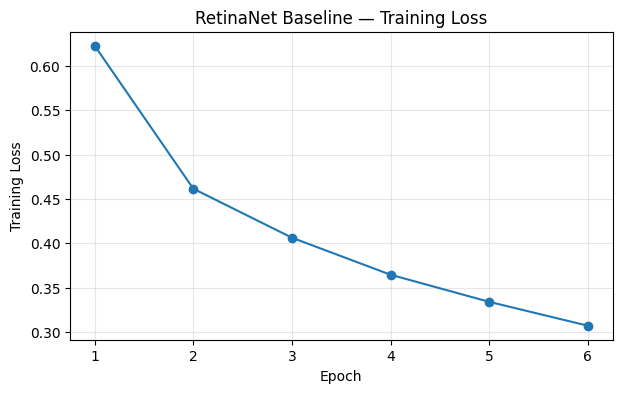

In [13]:

import matplotlib.pyplot as plt

train_losses = checkpoint["train_losses"]

plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("RetinaNet Baseline — Training Loss")
plt.xticks(range(1, len(train_losses) + 1))
plt.grid(alpha=0.3)
plt.show()


In [8]:

import time
import json
import numpy as np

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm.auto import tqdm


CLASS_NAMES = {
    1: "person",
    2: "bicycle",
    3: "car",
    4: "van",
    5: "truck",
    6: "tricycle",
    7: "bus",
    8: "motor"
}


def xyxy_to_xywh(box):
    x1, y1, x2, y2 = [float(v) for v in box]
    return [
        x1, y1,
        max(0.0, x2 - x1),
        max(0.0, y2 - y1)
    ]


def build_coco_gt(records):
    images = []
    annotations = []
    annotation_id = 1

    for rec in records:
        image_id = int(rec["image_id"])

        images.append({
            "id": image_id,
            "file_name": rec["file_name"]
        })

        for box, label in zip(rec["boxes"], rec["labels"]):
            bbox = xyxy_to_xywh(box)

            if bbox[2] <= 0 or bbox[3] <= 0:
                continue

            annotations.append({
                "id": annotation_id,
                "image_id": image_id,
                "category_id": int(label),
                "bbox": bbox,
                "area": bbox[2] * bbox[3],
                "iscrowd": 0
            })
            annotation_id += 1

        for box in rec["ignored_boxes"]:
            bbox = xyxy_to_xywh(box)

            if bbox[2] <= 0 or bbox[3] <= 0:
                continue

            for label in CLASS_NAMES:
                annotations.append({
                    "id": annotation_id,
                    "image_id": image_id,
                    "category_id": label,
                    "bbox": bbox,
                    "area": bbox[2] * bbox[3],
                    "iscrowd": 1
                })
                annotation_id += 1

    coco = COCO()
    coco.dataset = {
        "images": images,
        "annotations": annotations,
        "categories": [
            {"id": i, "name": name}
            for i, name in CLASS_NAMES.items()
        ],
        "info": {},
        "licenses": []
    }
    coco.createIndex()

    return coco


In [9]:

def evaluate_retinanet(model, data_loader, records):
    model.eval()

    predictions = []
    inference_times = []

    assert len(records) == len(data_loader.dataset)

    record_index = 0

    with torch.inference_mode():
        for images, _ in tqdm(data_loader, desc="Validation"):
            images_gpu = [
                image.to(DEVICE, non_blocking=True)
                for image in images
            ]

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()
            outputs = model(images_gpu)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            elapsed = time.perf_counter() - start
            inference_times.append(elapsed / len(images))

            for output in outputs:
                rec = records[record_index]
                image_id = int(rec["image_id"])
                record_index += 1

                boxes = output["boxes"].cpu().tolist()
                labels = output["labels"].cpu().tolist()
                scores = output["scores"].cpu().tolist()

                for box, label, score in zip(boxes, labels, scores):
                    if int(label) not in CLASS_NAMES:
                        continue

                    bbox = xyxy_to_xywh(box)

                    if bbox[2] <= 0 or bbox[3] <= 0:
                        continue

                    predictions.append({
                        "image_id": image_id,
                        "category_id": int(label),
                        "bbox": bbox,
                        "score": float(score)
                    })

    assert record_index == len(records)

    coco_gt = build_coco_gt(records)

    if predictions:
        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(coco_gt, coco_dt, iouType="bbox")
        evaluator.params.imgIds = [
            int(r["image_id"]) for r in records
        ]
        evaluator.params.catIds = list(CLASS_NAMES)
        evaluator.params.maxDets = [1, 10, 100]

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

        stats = [float(v) for v in evaluator.stats]
    else:
        stats = [0.0] * 12

    mean_time = float(np.mean(inference_times))

    metrics = {
        "mAP": stats[0],
        "AP50": stats[1],
        "AP75": stats[2],
        "AP_small": stats[3],
        "AP_medium": stats[4],
        "AP_large": stats[5],
        "inference_ms_per_image": mean_time * 1000,
        "FPS_equivalent_batch1": (
            1.0 / mean_time if mean_time > 0 else 0.0
        ),
        "images_evaluated": len(records),
        "num_predictions": len(predictions)
    }

    return metrics, predictions

In [16]:
fold_metrics, fold_predictions = evaluate_retinanet(
    model,
    val_loader,
    fold_val_data
)

(OUTPUT_DIR / "metrics_quick.json").write_text(
    json.dumps(fold_metrics, indent=2)
)

(OUTPUT_DIR / "predictions_quick.json").write_text(
    json.dumps(fold_predictions)
)

(OUTPUT_DIR / "config.json").write_text(
    json.dumps({
        "fold": FOLD,
        "epochs": EPOCHS,
        "train_frame_step": TRAIN_FRAME_STEP,
        "val_frame_step": VAL_FRAME_STEP,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "seed": SEED,
        "validation_images": len(fold_val_data),
        "evaluation_note": (
            "COCO-style evaluation with category-specific "
            "crowd annotations for ignored regions"
        )
    }, indent=2)
)

print("Fold:", FOLD)
print(json.dumps(fold_metrics, indent=2))
print("Results saved to:", OUTPUT_DIR)


Validation:   0%|          | 0/4044 [00:00<?, ?it/s]

creating index...
index created!
Loading and preparing results...
DONE (t=1.49s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=237.38s).
Accumulating evaluation results...
DONE (t=6.49s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.182
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.356
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.167
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.054
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.138
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.284
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.103
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.275
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.328
 Average Recall     (AR) @[ IoU=0

In [18]:
from zipfile import ZipFile, ZIP_DEFLATED

zip_path = Path("/kaggle/working/retinanet_fold_0_results.zip")

with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
    for file in fold_dir.iterdir():
        if file.is_file():
            z.write(file, arcname=f"fold_0/{file.name}")

print("Saved:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024**2, 2), "MB")

Saved: /kaggle/working/retinanet_fold_0_results.zip
Size: 374.53 MB


## Experiment 1 — Learning Rate Tuning

Перевіряємо, чи покращить результати зменшення learning rate з 1e-4 до 5e-5.

Навчаємо нову модель із тими самими параметрами та обробкою ignored regions, змінюючи лише learning rate.

In [ ]:

import torch
from pathlib import Path

from torchvision.models.detection import (
    retinanet_resnet50_fpn,
    RetinaNet_ResNet50_FPN_Weights
)
from torchvision.models.detection.retinanet import RetinaNetClassificationHead

EXP1_NAME = "lr_5e-5"
EXP1_LR = 5e-5
NUM_CLASSES = 9

assert FOLD == 0
assert DEVICE.type == "cuda"
assert len(train_dataset) > 0
assert len(val_dataset) > 0

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

model = retinanet_resnet50_fpn(
    weights=RetinaNet_ResNet50_FPN_Weights.DEFAULT
)

num_anchors = model.anchor_generator.num_anchors_per_location()[0]

model.head.classification_head = RetinaNetClassificationHead(
    model.backbone.out_channels,
    num_anchors,
    NUM_CLASSES
)

model = model.to(DEVICE)

print("Experiment:", EXP1_NAME)
print("Fold:", FOLD)
print("Fresh RetinaNet initialized")


Experiment: lr_5e-5
Fold: 0
Fresh RetinaNet initialized


In [12]:

from types import MethodType
from torchvision.ops import box_iou
from torchvision.models.detection.transform import resize_boxes
from torchvision.models.detection import _utils as det_utils

original_resize = model.transform.resize

def resize_with_ignore(image, target):
    old_size = image.shape[-2:]
    image, target = original_resize(image, target)

    if target is not None and "ignored_boxes" in target:
        target["ignored_boxes"] = resize_boxes(
            target["ignored_boxes"],
            old_size,
            image.shape[-2:]
        )

    return image, target

model.transform.resize = resize_with_ignore

def compute_loss_with_ignore(self, targets, head_outputs, anchors):
    matched_idxs = []

    for anchor, target in zip(anchors, targets):
        boxes = target["boxes"]

        if len(boxes):
            matches = self.proposal_matcher(box_iou(boxes, anchor))
        else:
            matches = torch.full(
                (len(anchor),),
                -1,
                dtype=torch.long,
                device=anchor.device
            )

        ignored = target.get("ignored_boxes")

        if ignored is not None and len(ignored):
            centers = (anchor[:, :2] + anchor[:, 2:]) / 2
            ignore_mask = torch.zeros(
                len(anchor),
                dtype=torch.bool,
                device=anchor.device
            )

            for box in ignored.unique(dim=0):
                ignore_mask |= (
                    (centers[:, 0] >= box[0]) &
                    (centers[:, 0] <= box[2]) &
                    (centers[:, 1] >= box[1]) &
                    (centers[:, 1] <= box[3])
                )

            matches[
                (matches < 0) & ignore_mask
            ] = det_utils.Matcher.BETWEEN_THRESHOLDS

        matched_idxs.append(matches)

    return self.head.compute_loss(
        targets, head_outputs, anchors, matched_idxs
    )

model.compute_loss = MethodType(compute_loss_with_ignore, model)

print("Ignored regions handling applied")


Ignored regions handling applied


In [13]:

from tqdm.auto import tqdm

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=EXP1_LR
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=DEVICE.type == "cuda"
)

OUTPUT_DIR = (
    Path("/kaggle/working/retinanet_tuning")
    / EXP1_NAME
    / f"fold_{FOLD}"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = OUTPUT_DIR / "fold_latest.pth"

assert not checkpoint_path.exists(), (
    f"Checkpoint already exists: {checkpoint_path}. "
    "Check whether this experiment has already been trained."
)

print("LR:", optimizer.param_groups[0]["lr"])
print("Output:", OUTPUT_DIR)


LR: 5e-05
Output: /kaggle/working/retinanet_tuning/lr_5e-5/fold_0


In [14]:

train_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for images, targets in tqdm(
        train_loader,
        desc=f"Fold {FOLD} | Epoch {epoch+1}/{EPOCHS}"
    ):
        images = [img.to(DEVICE) for img in images]
        targets = [
            {k: v.to(DEVICE) for k, v in t.items()}
            for t in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast("cuda", enabled=DEVICE.type == "cuda"):
            losses = model(images, targets)
            loss = sum(losses.values())

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch+1}"
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * len(images)

    epoch_loss = total_loss / len(train_dataset)
    train_losses.append(epoch_loss)

    payload = {
        "experiment": EXP1_NAME,
        "fold": FOLD,
        "epoch": epoch + 1,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "train_losses": train_losses,
        "train_frame_step": TRAIN_FRAME_STEP,
        "val_frame_step": VAL_FRAME_STEP,
        "epochs": EPOCHS,
        "lr": EXP1_LR
    }

    temp_path = checkpoint_path.with_suffix(".tmp")
    torch.save(payload, temp_path)
    temp_path.replace(checkpoint_path)

    print(
        f"Fold {FOLD} | Epoch {epoch+1}: "
        f"Loss = {epoch_loss:.4f}",
        flush=True
    )

print("Training finished")


Fold 0 | Epoch 1/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Fold 0 | Epoch 1: Loss = 0.6001


Fold 0 | Epoch 2/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c706f7e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c706f7e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Fold 0 | Epoch 2: Loss = 0.4462


Fold 0 | Epoch 3/6:   0%|          | 0/1353 [00:00<?, ?it/s]

... (6 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c706f7e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c706f7e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Fold 0 | Epoch 5: Loss = 0.3193


Fold 0 | Epoch 6/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Fold 0 | Epoch 6: Loss = 0.2941
Training finished


In [15]:

import json

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["fold"] == FOLD
assert checkpoint["epoch"] == EPOCHS
assert checkpoint["lr"] == EXP1_LR

model.load_state_dict(checkpoint["model"])
model.to(DEVICE)
model.eval()

exp1_metrics, exp1_predictions = evaluate_retinanet(
    model,
    val_loader,
    fold_val_data
)

(OUTPUT_DIR / "metrics_quick.json").write_text(
    json.dumps(exp1_metrics, indent=2)
)

(OUTPUT_DIR / "predictions_quick.json").write_text(
    json.dumps(exp1_predictions)
)

(OUTPUT_DIR / "config.json").write_text(
    json.dumps({
        "experiment": EXP1_NAME,
        "fold": FOLD,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": EXP1_LR,
        "seed": SEED,
        "train_frame_step": TRAIN_FRAME_STEP,
        "val_frame_step": VAL_FRAME_STEP,
        "validation_images": len(fold_val_data),
        "evaluation_note": (
            "COCO-style evaluation with category-specific "
            "crowd annotations for ignored regions"
        )
    }, indent=2)
)

print(json.dumps(exp1_metrics, indent=2))
print("Saved to:", OUTPUT_DIR)


Validation:   0%|          | 0/4044 [00:00<?, ?it/s]

creating index...
index created!
Loading and preparing results...
DONE (t=1.52s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=256.21s).
Accumulating evaluation results...
DONE (t=6.61s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.187
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.370
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.171
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.052
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.154
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.310
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.106
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.280
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.338
 Average Recall     (AR) @[ IoU=0

## 8. Experiment 2 — Focal Loss Modification

Змінюємо параметр alpha у Focal Loss з 0.25 до 0.5, щоб перевірити вплив балансу позитивних і негативних прикладів на якість детекції.

Learning rate залишаємо як у baseline (1e-4), а gamma = 2 та решту параметрів навчання не змінюємо.

In [17]:

import torch
from pathlib import Path

from torchvision.models.detection import (
    retinanet_resnet50_fpn,
    RetinaNet_ResNet50_FPN_Weights
)
from torchvision.models.detection.retinanet import (
    RetinaNetClassificationHead
)

EXP2_NAME = "focal_alpha_05"
EXP2_LR = 1e-4
EXP2_ALPHA = 0.5
EXP2_GAMMA = 2.0

assert FOLD == 0
assert DEVICE.type == "cuda"

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

model = retinanet_resnet50_fpn(
    weights=RetinaNet_ResNet50_FPN_Weights.DEFAULT
)

num_anchors = model.anchor_generator.num_anchors_per_location()[0]

model.head.classification_head = RetinaNetClassificationHead(
    model.backbone.out_channels,
    num_anchors,
    NUM_CLASSES
)

model = model.to(DEVICE)

print("Experiment:", EXP2_NAME)
print("LR:", EXP2_LR)
print("Focal alpha:", EXP2_ALPHA)
print("Fresh RetinaNet initialized")


Experiment: focal_alpha_05
LR: 0.0001
Focal alpha: 0.5
Fresh RetinaNet initialized


In [18]:

from types import MethodType
from torchvision.ops import sigmoid_focal_loss

def classification_loss_alpha05(
    self, targets, head_outputs, matched_idxs
):
    cls_logits = head_outputs["cls_logits"]
    losses = []

    for target, logits, matches in zip(
        targets, cls_logits, matched_idxs
    ):
        foreground = matches >= 0
        num_foreground = int(foreground.sum().item())

        gt_targets = torch.zeros_like(logits)

        gt_targets[
            foreground,
            target["labels"][matches[foreground]]
        ] = 1.0

        valid = matches != self.BETWEEN_THRESHOLDS

        cls_loss = sigmoid_focal_loss(
            logits[valid],
            gt_targets[valid],
            alpha=EXP2_ALPHA,
            gamma=EXP2_GAMMA,
            reduction="sum"
        )

        losses.append(
            cls_loss / max(1, num_foreground)
        )

    return torch.stack(losses).mean()


model.head.classification_head.compute_loss = MethodType(
    classification_loss_alpha05,
    model.head.classification_head
)

print(
    "Modified Focal Loss applied:",
    f"alpha={EXP2_ALPHA}, gamma={EXP2_GAMMA}"
)


Modified Focal Loss applied: alpha=0.5, gamma=2.0


In [19]:

from types import MethodType
from torchvision.ops import box_iou
from torchvision.models.detection.transform import resize_boxes
from torchvision.models.detection import _utils as det_utils

original_resize = model.transform.resize

def resize_with_ignore(image, target):
    old_size = image.shape[-2:]
    image, target = original_resize(image, target)

    if target is not None and "ignored_boxes" in target:
        target["ignored_boxes"] = resize_boxes(
            target["ignored_boxes"],
            old_size,
            image.shape[-2:]
        )

    return image, target

model.transform.resize = resize_with_ignore

def compute_loss_with_ignore(self, targets, head_outputs, anchors):
    matched_idxs = []

    for anchor, target in zip(anchors, targets):
        boxes = target["boxes"]

        if len(boxes):
            matches = self.proposal_matcher(box_iou(boxes, anchor))
        else:
            matches = torch.full(
                (len(anchor),),
                -1,
                dtype=torch.long,
                device=anchor.device
            )

        ignored = target.get("ignored_boxes")

        if ignored is not None and len(ignored):
            centers = (anchor[:, :2] + anchor[:, 2:]) / 2
            ignore_mask = torch.zeros(
                len(anchor),
                dtype=torch.bool,
                device=anchor.device
            )

            for box in ignored.unique(dim=0):
                ignore_mask |= (
                    (centers[:, 0] >= box[0]) &
                    (centers[:, 0] <= box[2]) &
                    (centers[:, 1] >= box[1]) &
                    (centers[:, 1] <= box[3])
                )

            matches[
                (matches < 0) & ignore_mask
            ] = det_utils.Matcher.BETWEEN_THRESHOLDS

        matched_idxs.append(matches)

    return self.head.compute_loss(
        targets, head_outputs, anchors, matched_idxs
    )

model.compute_loss = MethodType(compute_loss_with_ignore, model)

print("Ignored regions handling applied")


Ignored regions handling applied


In [20]:

from tqdm.auto import tqdm

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=EXP2_LR
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=DEVICE.type == "cuda"
)

OUTPUT_DIR = (
    Path("/kaggle/working/retinanet_tuning")
    / EXP2_NAME
    / f"fold_{FOLD}"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = OUTPUT_DIR / "fold_latest.pth"

assert not checkpoint_path.exists(), (
    f"Existing checkpoint: {checkpoint_path}"
)

assert optimizer.param_groups[0]["lr"] == 1e-4
assert EXP2_ALPHA == 0.5

print("Fold:", FOLD)
print("Experiment:", EXP2_NAME)
print("Output:", OUTPUT_DIR)


Fold: 0
Experiment: focal_alpha_05
Output: /kaggle/working/retinanet_tuning/focal_alpha_05/fold_0


In [21]:

train_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    total_cls = 0.0
    total_bbox = 0.0

    for images, targets in tqdm(
        train_loader,
        desc=f"Exp 2 | Fold {FOLD} | Epoch {epoch+1}/{EPOCHS}",
        leave=False
    ):
        images = [img.to(DEVICE) for img in images]
        targets = [
            {k: v.to(DEVICE) for k, v in t.items()}
            for t in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            "cuda",
            enabled=DEVICE.type == "cuda"
        ):
            losses = model(images, targets)
            loss = sum(losses.values())

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch+1}"
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        n = len(images)
        total_loss += loss.item() * n
        total_cls += losses["classification"].item() * n
        total_bbox += losses["bbox_regression"].item() * n

    epoch_loss = total_loss / len(train_dataset)
    epoch_cls = total_cls / len(train_dataset)
    epoch_bbox = total_bbox / len(train_dataset)

    train_losses.append(epoch_loss)

    payload = {
        "experiment": EXP2_NAME,
        "fold": FOLD,
        "epoch": epoch + 1,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "train_losses": train_losses,
        "epochs": EPOCHS,
        "lr": EXP2_LR,
        "focal_alpha": EXP2_ALPHA,
        "focal_gamma": EXP2_GAMMA,
        "train_frame_step": TRAIN_FRAME_STEP,
        "val_frame_step": VAL_FRAME_STEP,
    }

    temp_path = checkpoint_path.with_suffix(".tmp")
    torch.save(payload, temp_path)
    temp_path.replace(checkpoint_path)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Total={epoch_loss:.4f} | "
        f"Cls={epoch_cls:.4f} | "
        f"BBox={epoch_bbox:.4f}",
        flush=True
    )

print("Experiment 2 training finished")


Exp 2 | Fold 0 | Epoch 1/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Epoch 1/6 | Total=0.9047 | Cls=0.5868 | BBox=0.3179


Exp 2 | Fold 0 | Epoch 2/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c706f7e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c706f7e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 2/6 | Total=0.5834 | Cls=0.3203 | BBox=0.2631


Exp 2 | Fold 0 | Epoch 3/6:   0%|          | 0/1353 [00:00<?, ?it/s]

... (7 outputs left out)

Epoch 5/6 | Total=0.3975 | Cls=0.1823 | BBox=0.2152


Exp 2 | Fold 0 | Epoch 6/6:   0%|          | 0/1353 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c706f7e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c706f7e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 6/6 | Total=0.3671 | Cls=0.1617 | BBox=0.2054
Experiment 2 training finished


In [22]:

import json

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["fold"] == FOLD
assert checkpoint["epoch"] == EPOCHS
assert checkpoint["focal_alpha"] == EXP2_ALPHA

model.load_state_dict(checkpoint["model"])
model.to(DEVICE)
model.eval()

exp2_metrics, exp2_predictions = evaluate_retinanet(
    model,
    val_loader,
    fold_val_data
)

(OUTPUT_DIR / "metrics_quick.json").write_text(
    json.dumps(exp2_metrics, indent=2)
)

(OUTPUT_DIR / "predictions_quick.json").write_text(
    json.dumps(exp2_predictions)
)

(OUTPUT_DIR / "config.json").write_text(
    json.dumps({
        "experiment": EXP2_NAME,
        "fold": FOLD,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": EXP2_LR,
        "focal_alpha": EXP2_ALPHA,
        "focal_gamma": EXP2_GAMMA,
        "seed": SEED,
        "train_frame_step": TRAIN_FRAME_STEP,
        "val_frame_step": VAL_FRAME_STEP,
        "validation_images": len(fold_val_data),
        "evaluation_note": (
            "COCO-style evaluation with category-specific "
            "crowd annotations for ignored regions"
        )
    }, indent=2)
)

print(json.dumps(exp2_metrics, indent=2))
print("Saved to:", OUTPUT_DIR)


Validation:   0%|          | 0/4044 [00:09<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c706f7e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79c706f7e700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

creating index...
index created!
Loading and preparing results...
DONE (t=2.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=264.95s).
Accumulating evaluation results...
DONE (t=7.26s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.182
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.357
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.166
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.053
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.140
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.289
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.103
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.264
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.325
 Average Recall     (AR) @[ IoU=0

## 9. Порівняння результатів

Порівнюємо baseline та два tuning-експерименти на однаковому validation fold, щоб визначити, які зміни покращили якість детекції.

In [25]:

import json
import pandas as pd
from pathlib import Path

ROOT = Path("/kaggle/working")

experiments = {
    "Baseline": ROOT / "retinanet/fold_0",
    "Exp 1 — LR 5e-5": ROOT / "retinanet_tuning/lr_5e-5/fold_0",
    "Exp 2 — alpha 0.5": ROOT / "retinanet_tuning/focal_alpha_05/fold_0"
}

rows = []

for name, folder in experiments.items():
    metrics_path = folder / "metrics_quick.json"

    if not metrics_path.is_file():
        print("Not found:", metrics_path)
        continue

    with open(metrics_path) as f:
        metrics = json.load(f)

    rows.append({
        "Experiment": name,
        "mAP": metrics["mAP"],
        "AP50": metrics["AP50"],
        "AP75": metrics["AP75"],
        "AP_small": metrics["AP_small"],
        "AP_medium": metrics["AP_medium"],
        "AP_large": metrics["AP_large"],
    })

comparison = pd.DataFrame(rows)
display(comparison.round(4))


,Experiment,mAP,AP50,AP75,AP_small,AP_medium,AP_large
0,Baseline,0.1818,0.3556,0.1672,0.0537,0.1381,0.2837
1,Exp 1 — LR 5e-5,0.1871,0.3704,0.1707,0.0520,0.1537,0.3099
2,Exp 2 — alpha 0.5,0.1822,0.3568,0.1656,0.0531,0.1396,0.2890


### Висновок

Найкращий результат на Fold 0 отримано після зменшення learning rate до 5e-5: mAP зріс із 0.1818 до 0.1871. Найбільше покращення спостерігається для середніх і великих об'єктів, тоді як AP_small трохи знизився.

Зміна Focal Loss alpha до 0.5 дала лише незначне покращення (mAP = 0.1822). Остаточні висновки зробимо після порівняння результатів усіх трьох folds.

## 10. Збереження результатів

Перевіряємо наявність checkpoints, метрик і predictions та зберігаємо результати обох експериментів в один архів.

In [26]:

from pathlib import Path
from zipfile import ZipFile, ZIP_STORED

ROOT = Path("/kaggle/working")

experiments = {
    "lr_5e-5": ROOT / "retinanet_tuning/lr_5e-5/fold_0",
    "focal_alpha_05": ROOT / "retinanet_tuning/focal_alpha_05/fold_0",
}

required_files = [
    "fold_latest.pth",
    "metrics_quick.json",
    "predictions_quick.json",
    "config.json",
]

for exp_name, folder in experiments.items():
    print(f"\n{exp_name}")

    for name in required_files:
        path = folder / name
        assert path.is_file(), f"Missing: {path}"
        print("OK:", name, round(path.stat().st_size / 1024**2, 2), "MB")

zip_path = ROOT / "retinanet_fold0_tuning_results.zip"

with ZipFile(zip_path, "w", ZIP_STORED) as z:
    for exp_name, folder in experiments.items():
        for path in folder.iterdir():
            if path.is_file():
                z.write(
                    path,
                    arcname=f"{exp_name}/fold_0/{path.name}"
                )

with ZipFile(zip_path) as z:
    assert z.testzip() is None

print("\nZIP saved:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024**2, 1), "MB")
print("Both experiments archived successfully!")



lr_5e-5
OK: fold_latest.pth 368.68 MB
OK: metrics_quick.json 0.0 MB
OK: predictions_quick.json 183.11 MB
OK: config.json 0.0 MB

focal_alpha_05
OK: fold_latest.pth 368.68 MB
OK: metrics_quick.json 0.0 MB
OK: predictions_quick.json 201.5 MB
OK: config.json 0.0 MB

ZIP saved: /kaggle/working/retinanet_fold0_tuning_results.zip
Size: 1122.0 MB
Both experiments archived successfully!
